In [ ]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import layers, losses, optimizers, models, metrics
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
from tensorflow.keras.utils import register_keras_serializable

In [2]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()
tf.keras.mixed_precision.set_global_policy('float32')

In [ ]:
current_dir = Path.cwd()

In [ ]:
train = pd.read_csv(str(current_dir.parent / 'datasets/train_vae.csv'))
valid = pd.read_csv(str(current_dir.parent / 'datasets/valid_vae.csv'))
test = pd.read_csv(str(current_dir.parent / 'datasets/test_vae.csv'))
train_t = np.load(str(current_dir.parent / 'datasets/train_embeddings.npy'))
valid_t = np.load(str(current_dir.parent / 'datasets/valid_embeddings.npy'))
test_t = np.load(str(current_dir.parent / 'datasets/test_embeddings.npy'))

In [4]:
train_f = (train.iloc[:,5:-1].copy()).to_numpy()
valid_f = (valid.iloc[:,5:-1].copy()).to_numpy()
test_f = (test.iloc[:,3:-1].copy()).to_numpy()
y = (test.iloc[:,-1].copy()).to_numpy()
y_top = np.zeros(shape=(len(train_t) + len(valid_t),))
y = np.concatenate([y_top, y])
X_emb = np.vstack((train_t, valid_t, test_t))
X_feat = np.vstack((train_f, valid_f, test_f))
s_scaler_t = StandardScaler()
s_scaler_f = StandardScaler()
X_emb = s_scaler_t.fit_transform(X_emb)
X_feat = s_scaler_f.fit_transform(X_feat)
X = np.concatenate([X_emb, X_feat], axis=1)

In [ ]:
import joblib
joblib.dump(s_scaler_t, str(current_dir.parent / 'models/3lv_scaler_t_no_smoteen.pkl'))
joblib.dump(s_scaler_f, str(current_dir.parent / 'models/3lv_scaler_f_no_smoteen.pkl'))

['G:/Informatica/IA/enzimas/models/3lv_scaler_f_no_smoteen.pkl']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42, stratify=y_test)

In [6]:
X_train_emb = X_train[:,:1024].copy()
X_train_feat = X_train[:,1024:].copy()
X_valid_emb = X_valid[:,:1024].copy()
X_valid_feat = X_valid[:,1024:].copy()
X_test_emb = X_test[:,:1024].copy()
X_test_feat = X_test[:,1024:].copy()

In [7]:
def build_encoder_dnn(input_dim: tuple, units: list[tuple], activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    first_input = layers.Input(shape=(input_dim[0],), dtype=dtype)
    x = first_input
    for unit in units[0]:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    second_input = layers.Input(shape=(input_dim[1],), dtype=dtype)
    y = second_input
    for unit in units[1]:
        y = layers.Dense(unit, dtype=dtype)(y)
        y = activation(dtype=dtype)(y)
        y = layers.Dropout(dropout_rate)(y)
    x = layers.Concatenate()([x, y])
    mean = layers.Dense(latent_dim, dtype=dtype, name='mean')(x)
    log_var = layers.Dense(latent_dim, dtype=dtype, name='log_var')(x)
    encoder = models.Model([first_input, second_input], [mean, log_var], name="encoder")
    return encoder

def build_decoder_dnn(output_dim: tuple, units: list[tuple], activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    latent_inputs = layers.Input(shape=(latent_dim,), dtype=dtype)
    x = latent_inputs
    for unit in units[0]:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    y = latent_inputs
    for unit in units[1]:
        y = layers.Dense(unit, dtype=dtype)(x)
        y = activation(dtype=dtype)(x)
        y = layers.Dropout(dropout_rate)(x)
    first_output = layers.Dense(output_dim[0], activation='linear', dtype=dtype, name='first_output')(x)
    second_output = layers.Dense(output_dim[1], activation='linear', dtype=dtype, name='second_output')(y)
    decoder = models.Model(latent_inputs, [first_output, second_output], name="decoder")
    return decoder

def build_classifier(units: tuple, activation, latent_dim: int, dropout_rate: float = 0.1, dtype: tf.DType = tf.float32):
    input = layers.Input(shape=(latent_dim,))
    x = input
    for unit in units:
        x = layers.Dense(unit, dtype=dtype)(x)
        x = activation(dtype=dtype)(x)
        x = layers.Dropout(dropout_rate)(x)
    output = layers.Dense(1, name='logits_layer')(x)
    p_output = layers.Activation('sigmoid')(output)
    model = models.Model(inputs=input, outputs=p_output, name='classifier')
    return model
    
def sampling_reparameterization(distribution_params):
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

In [8]:
protbert_embed_dim = 1024
features_dim = 887
latent_dim = 128
batch_size = 32
epochs = 200
learning_rate = 1e-4
dtype = tf.float32
optimizer = optimizers.Adam(0.0005, clipnorm=1.0)
kl_weigth = 0.5
mse_emb_weigth = 1.0
mse_feat_weigth = 1.0
bce_weigth = 20.0
enc = build_encoder_dnn((protbert_embed_dim, features_dim), [(768, 512, 256), (512, 256)], layers.LeakyReLU, latent_dim)
dec = build_decoder_dnn((protbert_embed_dim, features_dim), [(256, 512, 768), (256, 512)], layers.LeakyReLU, latent_dim)
classifier = build_classifier((64, 32, 16), layers.LeakyReLU, latent_dim)

In [9]:
def mse_loss(y_true, y_pred):
    r_loss = tf.reduce_mean(tf.square(y_true - y_pred), axis=-1)
    return r_loss

def kl_loss(mean, log_var):
    epsilon = 1e-8
    kl_loss = -0.5 * tf.reduce_mean(1 + log_var - tf.square(mean) - tf.exp(log_var + epsilon), axis = -1)
    return kl_loss

def vae_loss(rec_emb, rec_feat, kl, bce):
    eps = tf.constant(1e-8, dtype=dtype)
    loss = (kl * kl_weigth) + (rec_emb * mse_emb_weigth) + (rec_feat * mse_feat_weigth) + (bce * bce_weigth)
    return loss
    

In [10]:

SKLEARN_BINARY_THRESHOLD = 0.5
SKLEARN_POS_LABEL = 1.0
SKLEARN_ZERO_DIVISION = 'warn'

def binarize_predictions_like_sklearn(y_pred, threshold=SKLEARN_BINARY_THRESHOLD):
    y_pred = np.asarray(y_pred).reshape(-1)
    return (y_pred > threshold).astype(np.int32)

def binarize_targets_like_sklearn(y_true, pos_label=SKLEARN_POS_LABEL):
    y_true = np.asarray(y_true).reshape(-1)
    return (y_true == pos_label).astype(np.int32)

@register_keras_serializable()
class BinaryF1Score(metrics.Metric):
    def __init__(self, name='f1_score', threshold=SKLEARN_BINARY_THRESHOLD, pos_label=SKLEARN_POS_LABEL, zero_division=SKLEARN_ZERO_DIVISION, dtype=tf.float32, **kwargs):
        super().__init__(name=name, dtype=dtype, **kwargs)
        self.threshold = float(threshold)
        self.pos_label = float(pos_label)
        self.zero_division = 0.0 if zero_division == 'warn' else float(zero_division)
        self.true_positives = self.add_weight(name='true_positives', initializer='zeros')
        self.pred_sum = self.add_weight(name='pred_sum', initializer='zeros')
        self.true_sum = self.add_weight(name='true_sum', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(tf.reshape(y_true, (-1,)), self.dtype)
        y_pred = tf.cast(tf.reshape(y_pred, (-1,)), self.dtype)
        y_true = tf.cast(tf.equal(y_true, tf.cast(self.pos_label, self.dtype)), self.dtype)
        y_pred = tf.cast(y_pred > self.threshold, self.dtype)

        if sample_weight is not None:
            sample_weight = tf.cast(tf.reshape(sample_weight, (-1,)), self.dtype)
        else:
            sample_weight = tf.ones_like(y_true, dtype=self.dtype)

        true_positives = tf.reduce_sum(sample_weight * y_true * y_pred)
        pred_sum = tf.reduce_sum(sample_weight * y_pred)
        true_sum = tf.reduce_sum(sample_weight * y_true)

        self.true_positives.assign_add(true_positives)
        self.pred_sum.assign_add(pred_sum)
        self.true_sum.assign_add(true_sum)

    def result(self):
        numerator = 2.0 * self.true_positives
        denominator = self.pred_sum + self.true_sum
        f1_score = tf.math.divide_no_nan(numerator, denominator)
        return tf.where(denominator > 0.0, f1_score, tf.cast(self.zero_division, self.dtype))

    def reset_state(self):
        self.true_positives.assign(0.0)
        self.pred_sum.assign(0.0)
        self.true_sum.assign(0.0)

    def get_config(self):
        config = super().get_config()
        config.update({'threshold': self.threshold, 'pos_label': self.pos_label, 'zero_division': self.zero_division})
        return config

@register_keras_serializable()
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, classifier, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder: models.Model = encoder
        self.decoder: models.Model = decoder
        self.classifier: models.Model = classifier
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.bce_loss_tracker = metrics.Mean(name='bce_loss')
        self.reconstruction_loss_emb_tracker = metrics.Mean(
            name="reconstruction_loss_emb"
        )
        self.reconstruction_loss_feat_tracker = metrics.Mean(
            name="reconstruction_loss_feat"
        )
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")
        self.accuracy_tracker = metrics.BinaryAccuracy(name='accuracy', threshold=SKLEARN_BINARY_THRESHOLD)
        self.precision_tracker = metrics.Precision(name='precision', thresholds=SKLEARN_BINARY_THRESHOLD)
        self.recall_tracker = metrics.Recall(name='recall', thresholds=SKLEARN_BINARY_THRESHOLD)
        self.auc_pr_tracker = metrics.AUC(name='auc_pr', curve='PR')
        self.f1_tracker = BinaryF1Score(name='f1_score', threshold=SKLEARN_BINARY_THRESHOLD, pos_label=SKLEARN_POS_LABEL, zero_division=SKLEARN_ZERO_DIVISION)
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_emb_tracker,
            self.reconstruction_loss_feat_tracker,
            self.bce_loss_tracker,
            self.kl_loss_tracker,
            self.accuracy_tracker,
            self.precision_tracker,
            self.recall_tracker,
            self.auc_pr_tracker,
            self.f1_tracker
        ]


    def call(self, inputs):
        mean, log_var = self.encoder(inputs)
        latent = sampling_reparameterization([mean, log_var])
        pred = self.classifier(latent)
        reconstructed_emb, reconstructed_feat = self.decoder(latent)
        return reconstructed_emb, reconstructed_feat, mean, log_var, pred

    def get_config(self):
        config = super().get_config()
        config.update({
            'encoder': self.encoder,
            'decoder': self.decoder,
            'classifier': self.classifier
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

    def _prepare_binary_data(self, y, pred):
        y = tf.cast(tf.reshape(y, (-1,)), tf.float32)
        pred = tf.cast(tf.reshape(pred, (-1,)), tf.float32)
        return y, pred

    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            reconstructed_emb, reconstructed_feat, mean, log_var, pred = self(X)
            emb, feat = X
            r_emb_loss = mse_loss(emb, reconstructed_emb)
            r_feat_loss = mse_loss(feat, reconstructed_feat)
            kl = kl_loss(mean, log_var)
            y_reshaped, pred_reshaped = self._prepare_binary_data(y, pred)
            bce_loss = losses.binary_crossentropy(y_reshaped, pred_reshaped)
            loss = vae_loss(r_emb_loss, r_feat_loss, kl, bce_loss)

        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        # Update metrics
        self.total_loss_tracker.update_state(loss)
        self.reconstruction_loss_emb_tracker.update_state(tf.reduce_mean(r_emb_loss))
        self.reconstruction_loss_feat_tracker.update_state(tf.reduce_mean(r_feat_loss))
        self.kl_loss_tracker.update_state(tf.reduce_mean(kl))
        self.bce_loss_tracker.update_state(tf.reduce_mean(bce_loss))

        self.accuracy_tracker.update_state(y_reshaped, pred_reshaped)
        self.f1_tracker.update_state(y_reshaped, pred_reshaped)
        self.precision_tracker.update_state(y_reshaped, pred_reshaped)
        self.recall_tracker.update_state(y_reshaped, pred_reshaped)
        self.auc_pr_tracker.update_state(y_reshaped, pred_reshaped)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        X, y = data
        reconstructed_emb, reconstructed_feat, mean, log_var, pred = self(X)
        emb, feat = X
        r_emb_loss = mse_loss(emb, reconstructed_emb)
        r_feat_loss = mse_loss(feat, reconstructed_feat)
        kl = kl_loss(mean, log_var)
        y_reshaped, pred_reshaped = self._prepare_binary_data(y, pred)
        bce_loss = losses.binary_crossentropy(y_reshaped, pred_reshaped)
        loss = vae_loss(r_emb_loss, r_feat_loss, kl, bce_loss)

        # Update metrics
        self.total_loss_tracker.update_state(loss)
        self.reconstruction_loss_emb_tracker.update_state(tf.reduce_mean(r_emb_loss))
        self.reconstruction_loss_feat_tracker.update_state(tf.reduce_mean(r_feat_loss))
        self.kl_loss_tracker.update_state(tf.reduce_mean(kl))
        self.bce_loss_tracker.update_state(tf.reduce_mean(bce_loss))
        self.accuracy_tracker.update_state(y_reshaped, pred_reshaped)
        self.f1_tracker.update_state(y_reshaped, pred_reshaped)
        self.precision_tracker.update_state(y_reshaped, pred_reshaped)

        self.recall_tracker.update_state(y_reshaped, pred_reshaped)
        self.auc_pr_tracker.update_state(y_reshaped, pred_reshaped)
        return {m.name: m.result() for m in self.metrics}
keras.utils.register_keras_serializable(package='CustomModels', name='VAE')(VAE)

__main__.VAE

In [ ]:
def train(train_data, test_data, epochs, enc, dec, classifier, optimizer):
    vae = VAE(enc, dec, classifier)
    vae.compile(optimizer=optimizer)
    early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    logger = tf.keras.callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_vae.csv'))
    history = vae.fit(train_data[0], train_data[1], epochs=epochs, validation_data=(test_data[0], test_data[1]), callbacks=[early_stopping, logger])
    return history, vae


history, model = train(((X_train_emb, X_train_feat), y_train.reshape((-1, 1))), ((X_test_emb, X_test_feat), y_test.reshape((-1, 1))), epochs, enc, dec, classifier, optimizer)

Epoch 1/200
770/770 ━━━━━━━━━━━━━━━━━━━━ 69s 72ms/step - accuracy: 0.9918 - auc_pr: 0.7200 - bce_loss: 0.0370 - f1_score: 0.6920 - kl_loss: 0.5239 - loss: 2.1613 - precision: 0.7808 - recall: 0.6213 - reconstruction_loss_emb: 0.4117 - reconstruction_loss_feat: 0.7479 - val_accuracy: 0.9987 - val_auc_pr: 0.9737 - val_bce_loss: 0.0091 - val_f1_score: 0.9545 - val_kl_loss: 0.3160 - val_loss: 1.3040 - val_precision: 1.0000 - val_recall: 0.9130 - val_reconstruction_loss_emb: 0.3277 - val_reconstruction_loss_feat: 0.6324
Epoch 2/200
770/770 ━━━━━━━━━━━━━━━━━━━━ 55s 71ms/step - accuracy: 0.9958 - auc_pr: 0.8505 - bce_loss: 0.0253 - f1_score: 0.8452 - kl_loss: 0.3051 - loss: 1.5736 - precision: 0.9311 - recall: 0.7738 - reconstruction_loss_emb: 0.2929 - reconstruction_loss_feat: 0.6226 - val_accuracy: 0.9971 - val_auc_pr: 0.9135 - val_bce_loss: 0.0204 - val_f1_score: 0.8916 - val_kl_loss: 0.2887 - val_loss: 1.4050 - val_precision: 1.0000 - val_recall: 0.8043 - val_reconstruction_loss_emb: 0.26

In [ ]:
model.encoder.save(str(current_dir.parent / 'models/vae_enc.keras'))
model.decoder.save(str(current_dir.parent / 'models/vae_dec.keras'))
model.classifier.save(str(current_dir.parent / 'models/vae_classifier.keras'))

In [ ]:
enc = keras.models.load_model(str(current_dir.parent / 'models/vae_enc.keras'))
dec = keras.models.load_model(str(current_dir.parent / 'models/vae_dec.keras'))
classifier = keras.models.load_model(str(current_dir.parent / 'models/vae_classifier.keras'))
model = VAE(enc, dec, classifier)

In [12]:
_, _, _, _, pred_train = model((X_train_emb, X_train_feat))
_, _, _, _, pred_valid = model((X_valid_emb, X_valid_feat))
pred_train = pred_train.numpy()
pred_valid = pred_valid.numpy()

In [13]:
y_train_eval = binarize_targets_like_sklearn(y_train)
y_valid_eval = binarize_targets_like_sklearn(y_valid)
pred_train = binarize_predictions_like_sklearn(pred_train, threshold=SKLEARN_BINARY_THRESHOLD)
pred_valid = binarize_predictions_like_sklearn(pred_valid, threshold=SKLEARN_BINARY_THRESHOLD)

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy training: 0.9990
Accuracy test: 0.9990
Precision training: 0.9777
Precision test: 1.0000
Recall training: 0.9537
Recall test: 0.9348
AUC training: 0.9767
AUC test: 0.9674
F1-score training: 0.9655
F1-score test: 0.9663
Clasification report training:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24263
           1       0.98      0.95      0.97       367

    accuracy                           1.00     24630
   macro avg       0.99      0.98      0.98     24630
weighted avg       1.00      1.00      1.00     24630

Clasification report test:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3033
           1       1.00      0.93      0.97        46

    accuracy                           1.00      3079
   macro avg       1.00      0.97      0.98      3079
weighted avg       1.00      1.00      1.00      3079



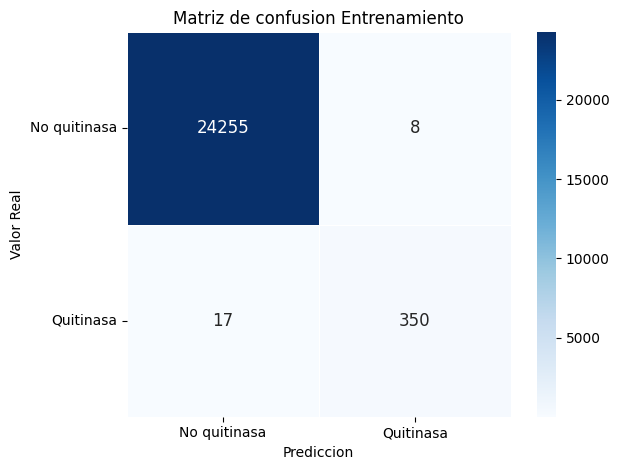

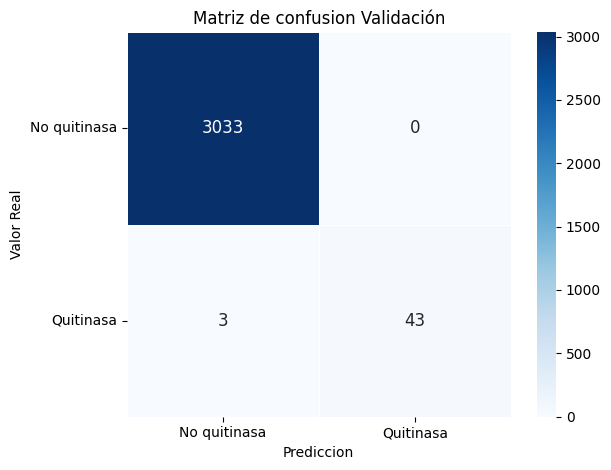

In [15]:
accuracy_t = accuracy_score(y_train_eval, pred_train)
accuracy_v = accuracy_score(y_valid_eval, pred_valid)
precision_t = precision_score(y_train_eval, pred_train)
precision_v = precision_score(y_valid_eval, pred_valid)
recall_t = recall_score(y_train_eval, pred_train)
recall_v = recall_score(y_valid_eval, pred_valid)
roc_auc_t = roc_auc_score(y_train_eval, pred_train)
roc_auc_v = roc_auc_score(y_valid_eval, pred_valid)
f1_t = f1_score(y_train_eval, pred_train)
f1_v = f1_score(y_valid_eval, pred_valid)
conf_matrix_t = confusion_matrix(y_train_eval, pred_train)
conf_matrix_v = confusion_matrix(y_valid_eval, pred_valid)
print(f"Accuracy training: {accuracy_t:.4f}")
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision training: {precision_t:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall training: {recall_t:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC training: {roc_auc_t:.4f}')
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score training: {f1_t:.4f}")
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report training:", classification_report(y_train_eval, pred_train), sep=f'\n')
print("Clasification report test:", classification_report(y_valid_eval, pred_valid), sep=f'\n')
class_labels = ['No quitinasa', 'Quitinasa']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

F1-score test: 0.9670
Clasification report test:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      3033
         1.0       0.98      0.96      0.97        46

    accuracy                           1.00      3079
   macro avg       0.99      0.98      0.98      3079
weighted avg       1.00      1.00      1.00      3079



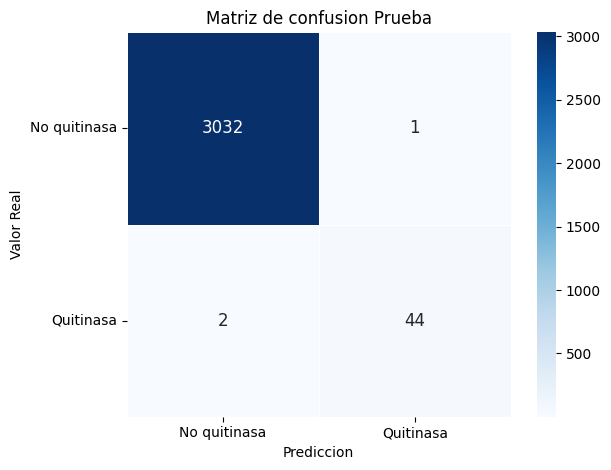

In [16]:
_, _, _, _, pred_test = model((X_test_emb, X_test_feat))
pred_test = pred_test.numpy()
pred_test = (pred_test > 0.5).astype(int)
y_test = y_test.reshape((-1, 1))
f1_t = f1_score(y_test, pred_test)
conf_matrix_t = confusion_matrix(y_test, pred_test)
print(f"F1-score test: {f1_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_vae.csv'))
history.head(10)

,epoch,accuracy,auc_pr,bce_loss,f1_score,kl_loss,loss,precision,recall,reconstruction_loss_emb,...,val_accuracy,val_auc_pr,val_bce_loss,val_f1_score,val_kl_loss,val_loss,val_precision,val_recall,val_reconstruction_loss_emb,val_reconstruction_loss_feat
0,0,0.991758,0.720035,0.036961,0.691958,0.523923,2.161313,0.780822,0.621253,0.411732,...,0.998701,0.973710,0.009074,0.954545,0.315959,1.303967,1.000000,0.913043,0.327705,0.632433
1,1,0.995777,0.850533,0.025258,0.845238,0.305130,1.573576,0.931148,0.773842,0.292947,...,0.997077,0.913529,0.020384,0.891566,0.288693,1.404968,1.000000,0.804348,0.269466,0.577443
2,2,0.996468,0.872978,0.024761,0.874820,0.296239,1.482571,0.926829,0.828338,0.258106,...,0.997402,0.896687,0.022259,0.904762,0.287399,1.385288,1.000000,0.826087,0.240434,0.549894
3,3,0.996143,0.858003,0.028726,0.860499,0.293052,1.513397,0.933121,0.798365,0.238449,...,0.996427,0.926497,0.016927,0.876405,0.279522,1.252136,0.906977,0.847826,0.228348,0.540386
4,4,0.995940,0.838339,0.027497,0.855908,0.293252,1.458798,0.908257,0.809264,0.226034,...,0.997727,0.913960,0.015214,0.926316,0.293111,1.215989,0.897959,0.956522,0.228088,0.532169
5,5,0.997077,0.890064,0.021127,0.897143,0.291920,1.307086,0.942943,0.855586,0.215824,...,0.995128,0.791504,0.042273,0.805195,0.284882,1.718290,1.000000,0.673913,0.204374,0.516984
6,6,0.996305,0.858488,0.027921,0.868307,0.293653,1.420080,0.925926,0.817439,0.207243,...,0.997727,0.930703,0.010664,0.921348,0.284164,1.063704,0.953488,0.891304,0.204397,0.500163
7,7,0.995777,0.842736,0.028239,0.851852,0.298112,1.414721,0.892537,0.814714,0.201628,...,0.997077,0.947889,0.014811,0.907216,0.292716,1.141686,0.862745,0.956522,0.197845,0.496869
8,8,0.996305,0.856804,0.026033,0.868307,0.299067,1.354429,0.925926,0.817439,0.195487,...,0.995778,0.910299,0.018817,0.860215,0.289230,1.215975,0.851064,0.869565,0.196970,0.493019
9,9,0.996549,0.873744,0.025908,0.878398,0.296224,1.336356,0.924699,0.836512,0.190168,...,0.996752,0.885175,0.020462,0.888889,0.298595,1.231988,0.909091,0.869565,0.186137,0.482128


In [17]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

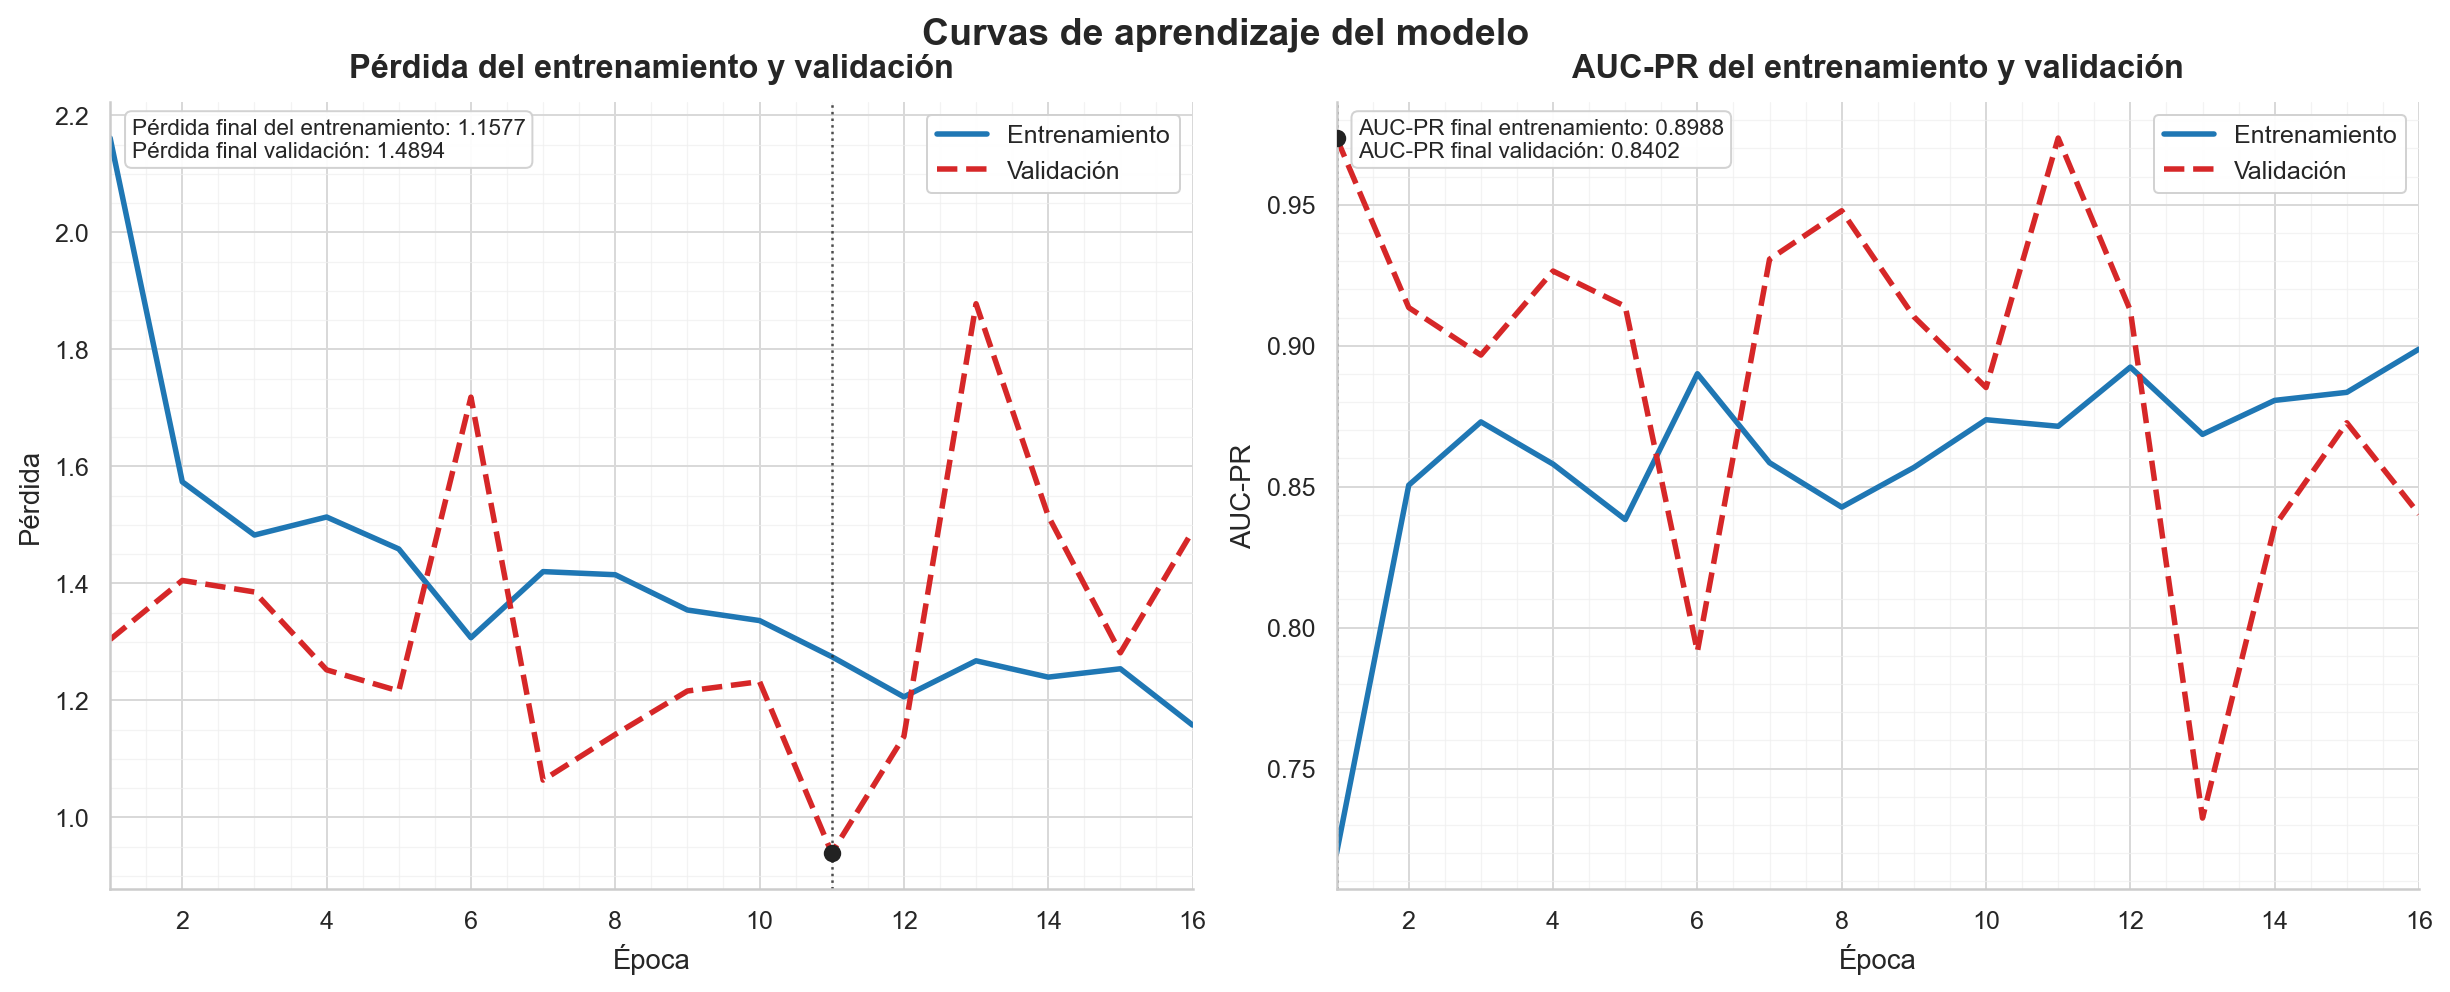

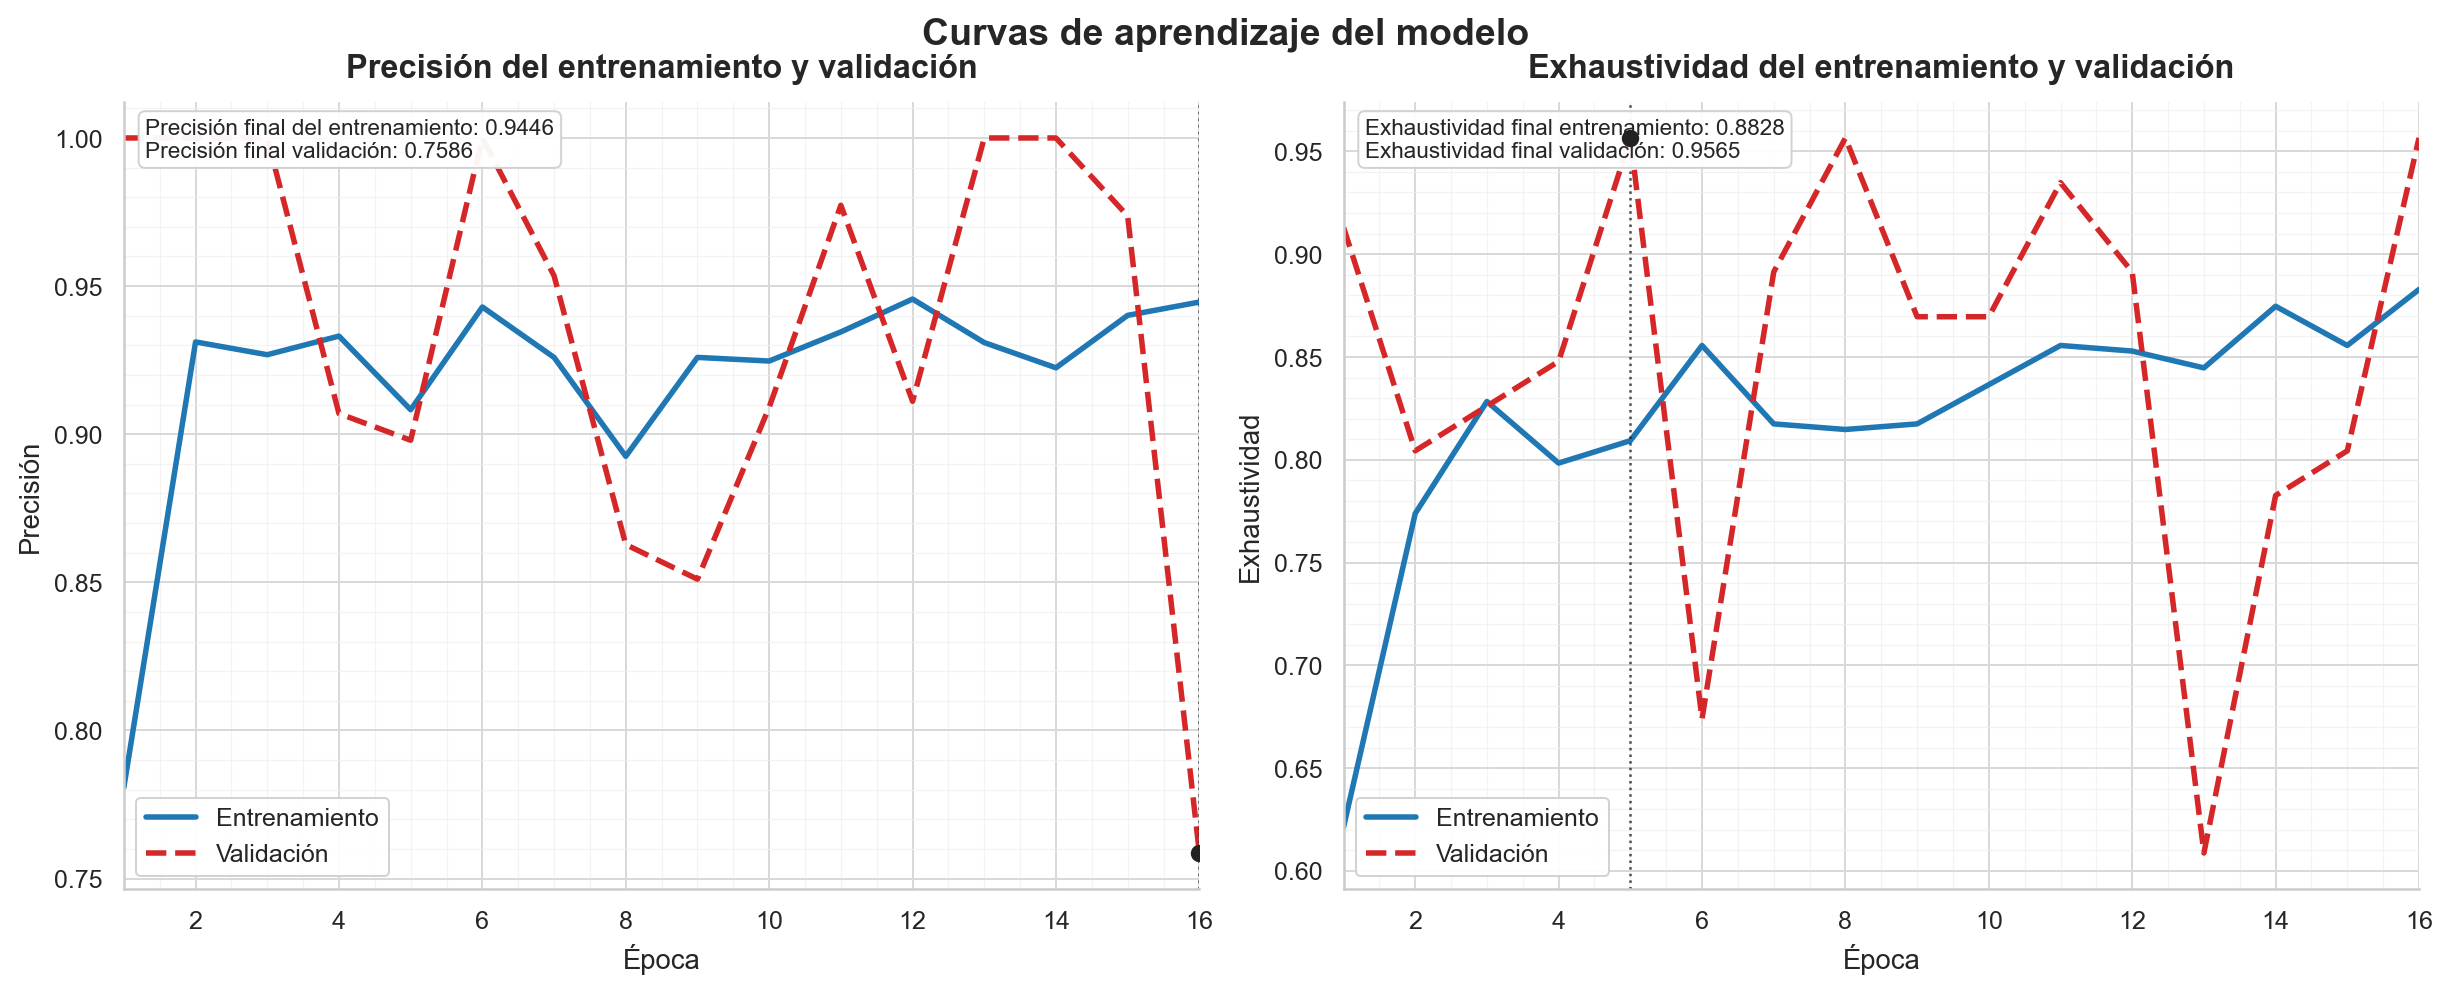

In [18]:
plot_charts(history, ('loss', 'auc_pr'), ('Pérdida', 'AUC-PR'))
plot_charts(history, ('precision', 'recall'), ('Precisión', 'Exhaustividad'))

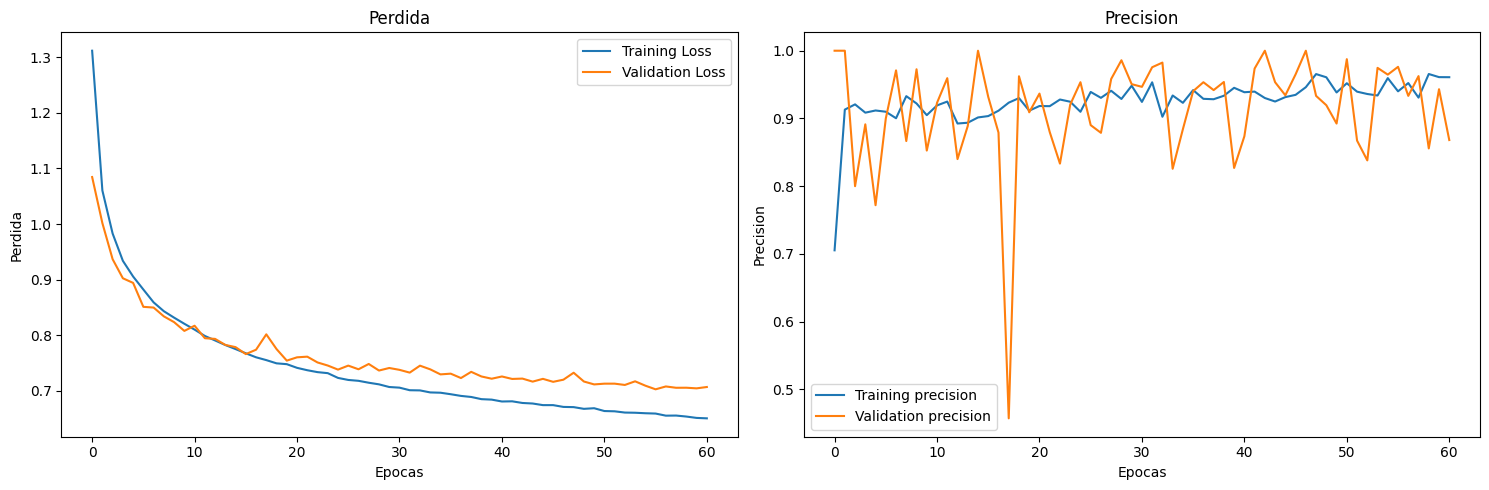

In [19]:
history_frame = history if isinstance(history, pd.DataFrame) else pd.DataFrame(history.history)
epochs = history_frame['epoch'] + 1 if 'epoch' in history_frame.columns else np.arange(1, len(history_frame) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(epochs, history_frame['loss'], label='Training loss')
axes[0].plot(epochs, history_frame['val_loss'], label='Validation loss')
axes[0].set_title('Perdida total')
axes[0].set_xlabel('Epocas')
axes[0].set_ylabel('Perdida')
axes[0].legend()

axes[1].plot(epochs, history_frame['f1_score'], label='Training F1 (scikit-like)')
axes[1].plot(epochs, history_frame['val_f1_score'], label='Validation F1 (scikit-like)')
axes[1].set_title('F1-score binario')
axes[1].set_xlabel('Epocas')
axes[1].set_ylabel('F1-score')
axes[1].legend()

plt.tight_layout()
plt.show()

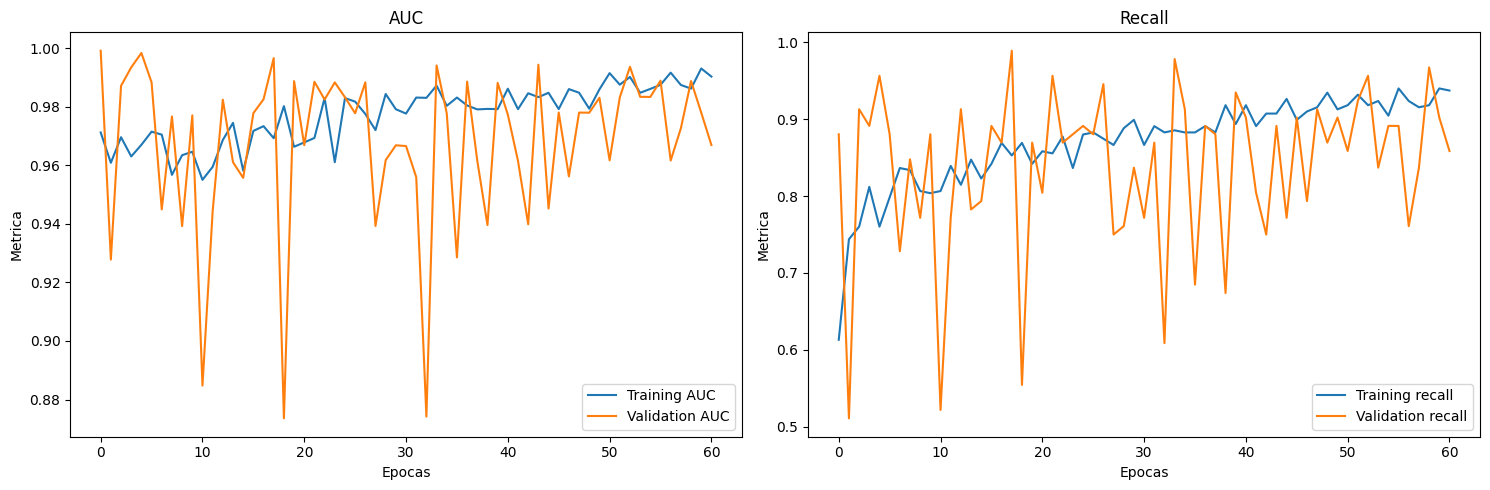

In [20]:
history_frame = history if isinstance(history, pd.DataFrame) else pd.DataFrame(history.history)
epochs = history_frame['epoch'] + 1 if 'epoch' in history_frame.columns else np.arange(1, len(history_frame) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(epochs, history_frame['auc_pr'], label='Training PR AUC')
axes[0].plot(epochs, history_frame['val_auc_pr'], label='Validation PR AUC')
axes[0].set_title('AUC-PR')
axes[0].set_xlabel('Epocas')
axes[0].set_ylabel('Metrica')
axes[0].legend()

axes[1].plot(epochs, history_frame['precision'], label='Training precision')
axes[1].plot(epochs, history_frame['val_precision'], label='Validation precision')
axes[1].plot(epochs, history_frame['recall'], label='Training recall')
axes[1].plot(epochs, history_frame['val_recall'], label='Validation recall')
axes[1].set_title('Precision y recall')
axes[1].set_xlabel('Epocas')
axes[1].set_ylabel('Metrica')
axes[1].legend()

plt.tight_layout()
plt.show()

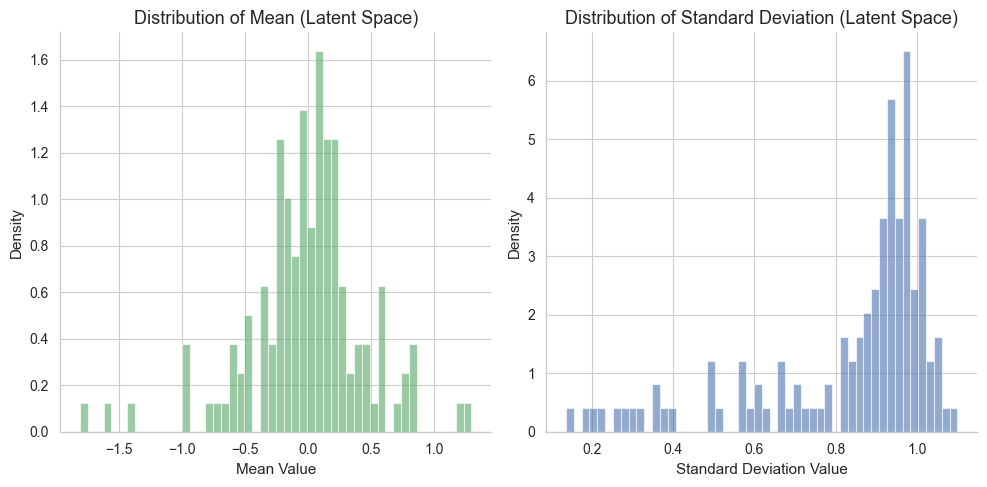

Mean of the latent means for sample 490: -0.0146
Standard deviation of the latent means for sample 490: 0.4642
Mean of the latent standard deviations for sample 490: 0.8317
Standard deviation of the latent standard deviations for sample 490: 0.2221


In [19]:
import matplotlib.pyplot as plt
sample_index = 490
#sample_data = data_reshaped[sample_index:sample_index+1]
sample_data = (X_test_emb[sample_index:sample_index+1], X_test_feat[sample_index:sample_index+1])
# Get the mean and log_var from the encoder
mean, log_var = model.encoder(sample_data)
std_dev = tf.exp(log_var * 0.5)

# Convert tensors to numpy arrays for plotting
mean_np = mean.numpy().flatten()
std_dev_np = std_dev.numpy().flatten()

# Plot the distribution of the mean
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(mean_np, bins=50, density=True, alpha=0.6, color='g')
plt.title('Distribution of Mean (Latent Space)')
plt.xlabel('Mean Value')
plt.ylabel('Density')

# Plot the distribution of the standard deviation
plt.subplot(1, 2, 2)
plt.hist(std_dev_np, bins=50, density=True, alpha=0.6, color='b')
plt.title('Distribution of Standard Deviation (Latent Space)')
plt.xlabel('Standard Deviation Value')
plt.ylabel('Density')

plt.tight_layout()
plt.show()

# You can also display some statistics
print(f"Mean of the latent means for sample {sample_index}: {np.mean(mean_np):.4f}")
print(f"Standard deviation of the latent means for sample {sample_index}: {np.std(mean_np):.4f}")
print(f"Mean of the latent standard deviations for sample {sample_index}: {np.mean(std_dev_np):.4f}")
print(f"Standard deviation of the latent standard deviations for sample {sample_index}: {np.std(std_dev_np):.4f}")